训练集 MSE: 203.0966
测试集 MSE: 183.6686
训练集 R² Score: 0.7195
测试集 R² Score: 0.7678
训练集 相关系数: 0.8484
测试集 相关系数: 0.8830


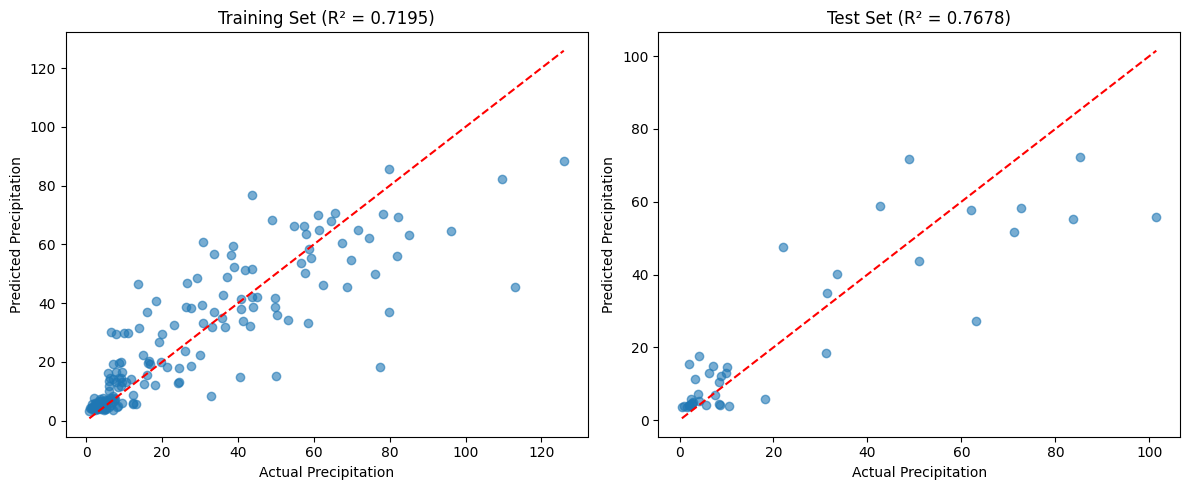

(161, 4) (41, 4)


ExactExplainer explainer: 42it [08:12, 12.32s/it]                        


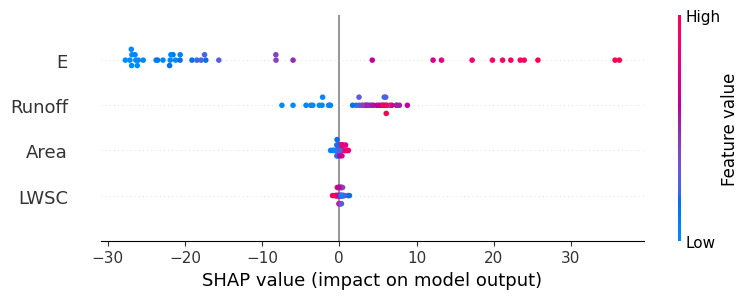

In [4]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
from tabpfn import TabPFNRegressor
import warnings
import shap

# 忽略警告
warnings.filterwarnings("ignore")

# 读取数据
df = pd.read_csv('data/machine_l.csv')

# 定义特征和目标变量
X = df[['LWSC', 'Runoff', 'E', 'Area']]
y = df['P']

# 划分训练集和测试集，比例为8:2
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 初始化TabPFN模型
model = TabPFNRegressor(model_path="model/tabpfn-v2-regressor.ckpt")

# 训练模型
model.fit(X_train, y_train)

# 预测
y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

# 计算评估指标
train_mse = mean_squared_error(y_train, y_pred_train)
test_mse = mean_squared_error(y_test, y_pred_test)
train_r2 = r2_score(y_train, y_pred_train)
test_r2 = r2_score(y_test, y_pred_test)
train_corr, _ = pearsonr(y_train, y_pred_train)
test_corr, _ = pearsonr(y_test, y_pred_test)

# 打印评估结果
print(f'训练集 MSE: {train_mse:.4f}')
print(f'测试集 MSE: {test_mse:.4f}')
print(f'训练集 R² Score: {train_r2:.4f}')
print(f'测试集 R² Score: {test_r2:.4f}')
print(f'训练集 相关系数: {train_corr:.4f}')
print(f'测试集 相关系数: {test_corr:.4f}')

# 可视化预测结果
plt.figure(figsize=(12, 5))

# 训练集预测结果
plt.subplot(1, 2, 1)
plt.scatter(y_train, y_pred_train, alpha=0.6)
plt.plot([y_train.min(), y_train.max()], [y_train.min(), y_train.max()], 'r--')
plt.xlabel('Actual Precipitation')
plt.ylabel('Predicted Precipitation')
plt.title(f'Training Set (R² = {train_r2:.4f})')

# 测试集预测结果
plt.subplot(1, 2, 2)
plt.scatter(y_test, y_pred_test, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Actual Precipitation')
plt.ylabel('Predicted Precipitation')
plt.title(f'Test Set (R² = {test_r2:.4f})')

plt.tight_layout()
plt.show()

# 使用SHAP进行特征重要性分析
print(X_train.shape, X_test.shape)

# 创建SHAP解释器
explainer = shap.Explainer(model.predict, X_train)
# 计算SHAP值
shap_values = explainer(X_test)
# 绘制SHAP摘要图
shap.summary_plot(shap_values, X_test)


<Figure size 1000x600 with 0 Axes>

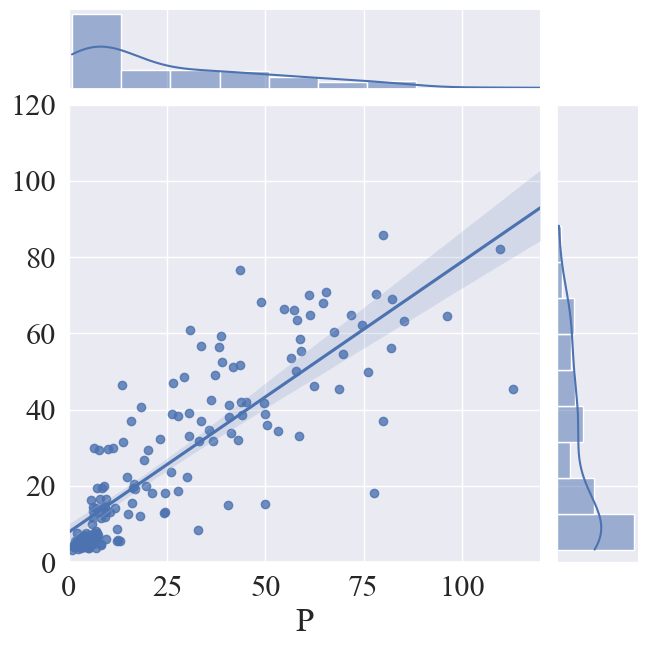

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
plt.figure(figsize=(10, 6))
rc = {'font.sans-serif': ['Times New Roman']}
sns.set(context='notebook', style="darkgrid", font_scale=2, rc=rc)
sns.jointplot(x=y_train, y=y_pred_train, 
                  kind="reg", truncate=False,
                  xlim=(0, 120), ylim=(0, 120),
                   height=7)


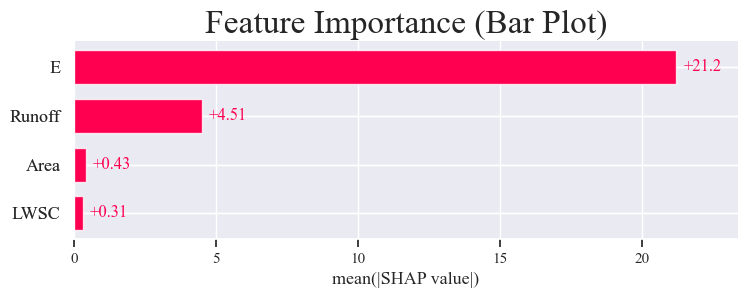

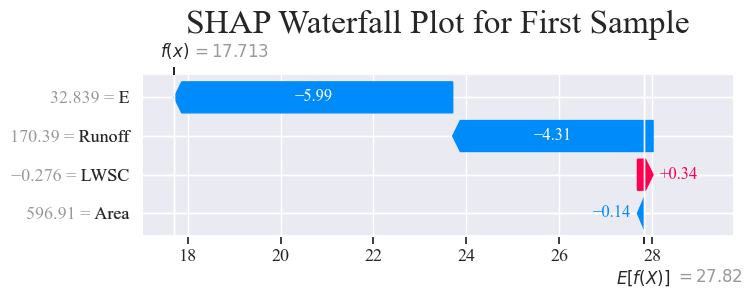

In [9]:
# 绘制SHAP条形图 - 显示特征的平均绝对SHAP值
plt.figure(figsize=(8, 6))
shap.plots.bar(shap_values, show=False)
plt.title('Feature Importance (Bar Plot)')
plt.tight_layout()
plt.show()

# 绘制SHAP瀑布图 - 展示单个预测的解释
plt.figure(figsize=(10, 6))
# 选择第一个样本进行解释
shap.plots.waterfall(shap_values[0], show=False)
plt.title('SHAP Waterfall Plot for First Sample')
plt.tight_layout()
plt.show()


plt.show()
